# Predicting Post-Fire Permafrost Thaw Using the FireALT Dataset
COSC 74, Gary Ding, November 19th, 2026

## 0. Setup

In [ ]:
import os, sys, time, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, LeaveOneGroupOut
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
SEED = 74
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
COLORS = ["#262622", "#586872", "#806536", "#e8c589"]  # char ink, smoke slate, tundra ochre, sunlit tundra (sampled from slide photos); fixed order
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

In [ ]:
# Data: Talucci et al. (2024), FireALT dataset, NSF Arctic Data Center, doi:10.18739/A2RN3092P (CC BY 4.0)
DATA_URL = "https://arcticdata.io/metacat/d1/mn/v2/object/urn:uuid:c424189c-3ef2-4c98-8656-cfb26664ad6a"
FILE = "FireAltEstimatedRawData.csv"
if not os.path.exists(FILE):
    urllib.request.urlretrieve(DATA_URL, FILE)
print(f"{FILE}: {os.path.getsize(FILE)/1e6:.1f} MB")

FireAltEstimatedRawData.csv: 11.2 MB


## 1. Preprocessing

In [ ]:
raw = pd.read_csv(FILE).replace([-9999, "-9999"], np.nan)    # -9999 -> missing
raw["tsf_num"] = pd.to_numeric(raw["tsf"], errors="coerce")   # unburned "u" -> missing

# Average repeated probes to one row per plot per year
PLOT_KEYS = ["submitNm", "distur", "siteId", "plotId", "fireYr", "year"]
NUM_MEAN  = ["estDepth", "orgDepth", "lat", "lon", "tsf_num", "msrDepth", "msrDoy", "estDoy"]
FIRST     = ["cntryId", "biome", "fireId", "paired", "srfH2O", "topoPos", "slope", "vegCvr",
             "msrType", "tsfClass", "resName", "permaExtent"]

g = raw.groupby(PLOT_KEYS, dropna=False)
d = g[NUM_MEAN].mean().join(g[FIRST].first()).reset_index()
d["site"] = d["submitNm"] + "|" + d["siteId"].astype(str)
d["region"] = d["cntryId"].map({"US": "Alaska", "CA": "Canada", "RU": "Russia"})

print(f"Raw rows: {len(raw):,}  ->  plot-year rows: {len(d):,}")
print(f"Sites: {d.site.nunique()}, contributors: {d.submitNm.nunique()}, fires: {d.fireId.nunique()}")

Raw rows: 48,669  ->  plot-year rows: 9,446
Sites: 197, contributors: 18, fires: 81


## 2. Features

In [ ]:
TARGET = "estDepth"
burned = d["distur"] == "burned"
d["tsf"]  = np.where(burned, d["tsf_num"], 0.0)   # unburned -> 0 years
d["tsf2"] = d["tsf"] ** 2                          # squared term

CAT = ["distur", "biome", "vegCvr", "slope", "topoPos", "srfH2O", "resName", "permaExtent"]
NUM = ["tsf", "tsf2"]

# Left out: site-specific features (Section 6)
EXTRA = {"coordinates": ["lat", "lon"], "year": ["year"], "organic layer depth": ["orgDepth"]}
# Left out: fields the label is computed from (Section 7)
LEAKY_CAT, LEAKY_NUM = ["msrType"], ["msrDepth", "msrDoy", "estDoy"]

y = d[TARGET].to_numpy()
print(d[TARGET].describe().round(1))
print("\nMissing values in kept features:")
print(d[CAT + NUM].isna().sum()[lambda s: s > 0])

count    9446.0
mean       72.5
std        33.4
min         0.0
25%        54.0
50%        63.0
75%        80.0
max       371.0
Name: estDepth, dtype: float64

Missing values in kept features:
vegCvr       4
slope       68
topoPos    209
srfH2O      68
tsf          1
tsf2         1
dtype: int64


## 3. Cross-validation splits

### 3a. Fire groups

In [ ]:
# Start with one group per pair code (or per site if no pair code),
# then merge groups that share a fire ID (burned or unburned plots) until nothing changes
d["pair_key"] = np.where(d["paired"].notna(), "pair:" + d["submitNm"] + "|" + d["paired"].astype(str),
                         "site:" + d["site"])
d["fire_group"] = d["pair_key"]
has_fire = d["fireId"].notna()
while True:
    before = d["fire_group"].copy()
    d.loc[has_fire, "fire_group"] = d[has_fire].groupby("fireId")["fire_group"].transform("min")
    d["fire_group"] = d.groupby("pair_key")["fire_group"].transform("min")
    if d["fire_group"].equals(before):
        break

fg = d.groupby("fire_group").agg(n=(TARGET, "size"), burned=("distur", lambda s: (s == "burned").sum()))
print(f"Fire groups: {len(fg)} | median size {fg.n.median():.0f} plot-years, largest {fg.n.max()}")
print(f"Groups with both burned and unburned plots: {((fg.burned > 0) & (fg.burned < fg.n)).sum()}")

# Plot-years by burn status, fire ID and pair code
display(pd.crosstab(d["distur"], [d["fireId"].notna().rename("has fire ID"),
                                  d["paired"].notna().rename("has pair code")], margins=True))

# Plot-years by burn status and the make-up of the fire group they end up in
has_b = d.groupby("fire_group")["distur"].transform(lambda s: (s == "burned").any())
has_u = d.groupby("fire_group")["distur"].transform(lambda s: (s == "unburned").any())
d["group_makeup"] = np.select([has_b & has_u, has_b], ["burned + unburned", "burned only"], "unburned only")
display(pd.crosstab(d["distur"], d["group_makeup"], margins=True))

Fire groups: 59 | median size 16 plot-years, largest 2141
Groups with both burned and unburned plots: 53


has fire ID   False        True         All
has pair code False  True False  True      
distur                                     
burned            5  2767     5  1805  4582
unburned          0  4421     4   439  4864
All               5  7188     9  2244  9446

group_makeup,burned + unburned,burned only,unburned only,All
distur,,,,
burned,4572,10,0,4582
unburned,4862,0,2,4864
All,9434,10,2,9446


### 3b. Splits

In [ ]:
idx = np.arange(len(d))
north_america = d["region"].isin(["Alaska", "Canada"]).to_numpy()
SPLITS = {
    "Random (5-fold)":       list(KFold(5, shuffle=True, random_state=SEED).split(idx)),
    "By site (5-fold)":      list(GroupKFold(5).split(idx, groups=d["site"])),
    "By fire (5-fold)":      list(GroupKFold(5).split(idx, groups=d["fire_group"])),
    "Leave-contributor-out": list(LeaveOneGroupOut().split(idx, groups=d["submitNm"])),
    "Alaska -> Canada":      [(idx[d.region == "Alaska"], idx[d.region == "Canada"])],
    "N. America -> Russia":  [(idx[north_america], idx[~north_america])],
}
split_info = pd.DataFrame({s: {"folds": len(f), "mean test size": int(np.mean([len(t) for _, t in f])),
                               "min test size": min(len(t) for _, t in f)} for s, f in SPLITS.items()}).T
display(split_info)
print(f"Total folds: {split_info['folds'].sum()}")

,folds,mean test size,min test size
Random (5-fold),5,1889,1889
By site (5-fold),5,1889,1877
By fire (5-fold),5,1889,1826
Leave-contributor-out,18,524,3
Alaska -> Canada,1,4584,4584
N. America -> Russia,1,691,691


Total folds: 35


## 4. Models

In [ ]:
def make_prep(cat, num):
    # categorical: missing -> "missing", one-hot; numeric: median fill + missing flag, standardize
    return ColumnTransformer([
        ("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
        ("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), num)])


class GroupMeanBaseline:
    # Mean ALT per (biome, permafrost extent, burn status); falls back to coarser groups, then overall mean
    keys = ["biome", "permaExtent", "distur"]
    def fit(self, X, y):
        X = X.assign(_y=np.asarray(y))
        self.overall = X["_y"].mean()
        self.tables = [X.groupby(self.keys[:k])["_y"].mean() for k in (3, 2, 1)]
        return self
    def predict(self, X):
        pred = pd.Series(np.nan, index=X.index)
        for tab in self.tables:
            cols = list(tab.index.names)
            look = X[cols].merge(tab.rename("m").reset_index(), on=cols, how="left")["m"].to_numpy()
            pred = pred.fillna(pd.Series(look, index=X.index))
        return pred.fillna(self.overall).to_numpy()


# Hyperparameter grids
GRIDS = {
    "Ridge": [0.1, 1, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8],
    "Lasso": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3],
    "KNN":   [1, 3, 5, 15, 50, 150, 500],
}
PARAM = {"Ridge": "regressor__model__alpha", "Lasso": "regressor__model__alpha",
         "KNN": "regressor__model__n_neighbors"}


def make_models(cat=CAT, num=NUM, names=None):
    # name -> (function that builds a fresh model, hyperparameter grid or None)
    # learned models: fit on log(1 + ALT), predict in cm
    def learned(model_cls, **kw):
        return lambda: TransformedTargetRegressor(
            Pipeline([("prep", make_prep(cat, num)), ("model", model_cls(**kw))]),
            func=np.log1p, inverse_func=np.expm1)
    grid = lambda name: {PARAM[name]: GRIDS[name]}
    models = {
        "Median baseline":     (lambda: DummyRegressor(strategy="median"), None),
        "Group-mean baseline": (lambda: GroupMeanBaseline(), None),
        "Linear regression":   (learned(LinearRegression), None),
        "Ridge":               (learned(Ridge), grid("Ridge")),
        "Lasso":               (learned(Lasso, max_iter=20000), grid("Lasso")),
        "KNN":                 (learned(KNeighborsRegressor), grid("KNN")),
    }
    return models if names is None else {n: models[n] for n in names}


def fit_model(make, grid, X, y, groups):
    # Tune with 3-fold CV grouped by site inside the training set
    if grid is None:
        return make().fit(X, y), np.nan
    search = GridSearchCV(make(), grid, cv=GroupKFold(3), scoring="neg_mean_absolute_error", n_jobs=-1)
    search.fit(X, y, groups=groups)
    return search.best_estimator_, list(search.best_params_.values())[0]


def run_split(split_name, models, cols):
    # Train every model on every fold of one split; one row per held-out prediction
    X, rows = d[cols], []
    for k, (tr, te) in enumerate(SPLITS[split_name]):
        for name, (make, grid) in models.items():
            m, param = fit_model(make, grid, X.iloc[tr], y[tr], d["site"].to_numpy()[tr])
            rows.append(pd.DataFrame({"split": split_name, "model": name, "fold": k, "row": te,
                                      "pred": m.predict(X.iloc[te]), "param": param}))
    return pd.concat(rows, ignore_index=True)


def score(preds, by=("split", "model")):
    # MAE, RMSE, R² over all held-out rows; fold-to-fold SD of MAE
    out = []
    for key, g in preds.groupby(list(by), sort=False):
        t = y[g["row"]]
        fold_mae = [mean_absolute_error(y[f["row"]], f["pred"]) for _, f in g.groupby("fold")]
        out.append(dict(zip(by, key), MAE=mean_absolute_error(t, g["pred"]),
                        RMSE=np.sqrt(mean_squared_error(t, g["pred"])), R2=r2_score(t, g["pred"]),
                        **{"MAE fold SD": np.std(fold_mae, ddof=1) if len(fold_mae) > 1 else np.nan}))
    return pd.DataFrame(out).set_index(list(by)).round(2)

## 5. All models under all splits

### 5a. Training and scoring

In [ ]:
MODELS = make_models()
t0 = time.time()
all_preds = []
for s in SPLITS:
    t = time.time()
    all_preds.append(run_split(s, MODELS, CAT + NUM))
    print(f"{s:24s} done in {time.time() - t:5.0f} s")
all_preds = pd.concat(all_preds, ignore_index=True)
print(f"Total: {(time.time() - t0) / 60:.1f} min")

Random (5-fold)          done in    91 s
By site (5-fold)         done in    88 s
By fire (5-fold)         done in    87 s
Leave-contributor-out    done in   413 s
Alaska -> Canada         done in     6 s
N. America -> Russia     done in    14 s
Total: 11.6 min


In [ ]:
results = score(all_preds)
model_order, split_order = list(MODELS), list(SPLITS)
metric_table = lambda m: results[m].unstack("split").loc[model_order, split_order]
mae_table, rmse_table, r2_table = metric_table("MAE"), metric_table("RMSE"), metric_table("R2")

print("MAE (cm)");  display(mae_table)
print("RMSE (cm)"); display(rmse_table)
print("R²");        display(r2_table)
print("Fold-to-fold SD of MAE (cm)")
display(results["MAE fold SD"].unstack("split").loc[model_order, split_order[:4]])

MAE (cm)


split,Random (5-fold),By site (5-fold),By fire (5-fold),Leave-contributor-out,Alaska -> Canada,N. America -> Russia
model,,,,,,
Median baseline,20.21,20.67,20.47,20.78,22.80,24.89
Group-mean baseline,19.05,20.31,22.69,33.37,27.06,27.67
Linear regression,17.75,27.13,22.30,66.90,27.66,21.00
Ridge,20.61,27.44,20.02,20.09,21.68,27.29
Lasso,19.21,26.35,19.39,20.05,21.68,27.60
KNN,16.71,28.00,20.71,22.66,48.98,17.80


RMSE (cm)


split,Random (5-fold),By site (5-fold),By fire (5-fold),Leave-contributor-out,Alaska -> Canada,N. America -> Russia
model,,,,,,
Median baseline,34.72,35.10,34.84,35.25,34.05,34.18
Group-mean baseline,29.72,31.10,34.01,44.94,38.98,35.13
Linear regression,29.91,38.54,35.83,90.07,33.87,31.81
Ridge,33.83,38.73,32.80,33.20,31.89,35.24
Lasso,32.38,37.66,32.07,33.06,31.89,35.22
KNN,24.84,39.04,32.78,34.64,74.93,26.79


R²


split,Random (5-fold),By site (5-fold),By fire (5-fold),Leave-contributor-out,Alaska -> Canada,N. America -> Russia
model,,,,,,
Median baseline,-0.08,-0.11,-0.09,-0.12,-0.35,-0.03
Group-mean baseline,0.21,0.13,-0.04,-0.81,-0.76,-0.09
Linear regression,0.20,-0.33,-0.15,-6.28,-0.33,0.11
Ridge,-0.03,-0.35,0.03,0.01,-0.18,-0.09
Lasso,0.06,-0.27,0.08,0.02,-0.18,-0.09
KNN,0.45,-0.37,0.04,-0.08,-5.52,0.37


Fold-to-fold SD of MAE (cm)


split,Random (5-fold),By site (5-fold),By fire (5-fold),Leave-contributor-out
model,,,,
Median baseline,0.32,8.19,2.37,32.19
Group-mean baseline,0.29,6.41,3.85,30.66
Linear regression,0.28,12.77,3.67,33.69
Ridge,0.31,11.17,2.36,30.61
Lasso,0.30,10.07,1.92,30.47
KNN,1.81,7.75,3.73,33.03


### 5b. Chosen hyperparameters

In [ ]:
tuned = all_preds[all_preds.param.notna()].drop_duplicates(["split", "model", "fold"])
chosen = (tuned.groupby(["model", "split"])["param"].agg(lambda s: f"{s.value_counts().index[0]:g}")
          .unstack("split"))
print("Most often chosen value, per model and split")
display(chosen[split_order])

Most often chosen value, per model and split


split,Random (5-fold),By site (5-fold),By fire (5-fold),Leave-contributor-out,Alaska -> Canada,N. America -> Russia
model,,,,,,
KNN,15,5,500,15,15,15
Lasso,0.03,0.03,0.03,0.03,0.1,0.03
Ridge,1e+08,1e+08,1e+08,1e+08,1e+08,1e+08


### 5c. Validation curves

In [ ]:
# CV MAE across each hyperparameter grid on all data: training error, random 5-fold, site-grouped 5-fold
curves = {}
for name in ["Ridge", "Lasso", "KNN"]:
    make, grid = make_models(names=[name])[name]
    out = {}
    for label, cv in [("random 5-fold", KFold(5, shuffle=True, random_state=SEED)), ("by site 5-fold", GroupKFold(5))]:
        s = GridSearchCV(make(), grid, cv=cv, scoring="neg_mean_absolute_error",
                         return_train_score=True, n_jobs=-1).fit(d[CAT + NUM], y, groups=d["site"])
        out[f"validation, {label}"] = -s.cv_results_["mean_test_score"]
        out["training"] = -s.cv_results_["mean_train_score"]
    curves[name] = pd.DataFrame(out, index=pd.Index(GRIDS[name], name=PARAM[name].split("__")[-1])).round(2)
    print(name); display(curves[name])

Ridge


,"validation, random 5-fold",training,"validation, by site 5-fold"
alpha,,,
0.1,17.75,17.40,26.98
1.0,17.74,17.41,26.87
10.0,17.74,17.44,26.32
100.0,17.84,17.59,24.94
1000.0,18.18,18.00,22.29
10000.0,19.52,19.38,21.16
100000.0,20.44,20.36,21.19
1000000.0,20.60,20.53,21.20
10000000.0,20.61,20.55,21.20


Lasso


,"validation, random 5-fold",training,"validation, by site 5-fold"
alpha,,,
0.0003,17.74,17.45,26.24
0.0010,17.83,17.57,25.49
0.0030,18.03,17.80,24.28
0.0100,18.28,18.11,21.87
0.0300,19.21,19.13,20.27
0.1000,20.61,20.55,21.20
0.3000,20.61,20.55,21.20


KNN


,"validation, random 5-fold",training,"validation, by site 5-fold"
n_neighbors,,,
1,20.45,19.01,23.44
3,17.45,16.16,21.01
5,16.56,15.95,21.50
15,15.41,15.08,20.29
50,15.39,15.27,21.10
150,16.50,16.25,25.05
500,18.03,17.71,25.66


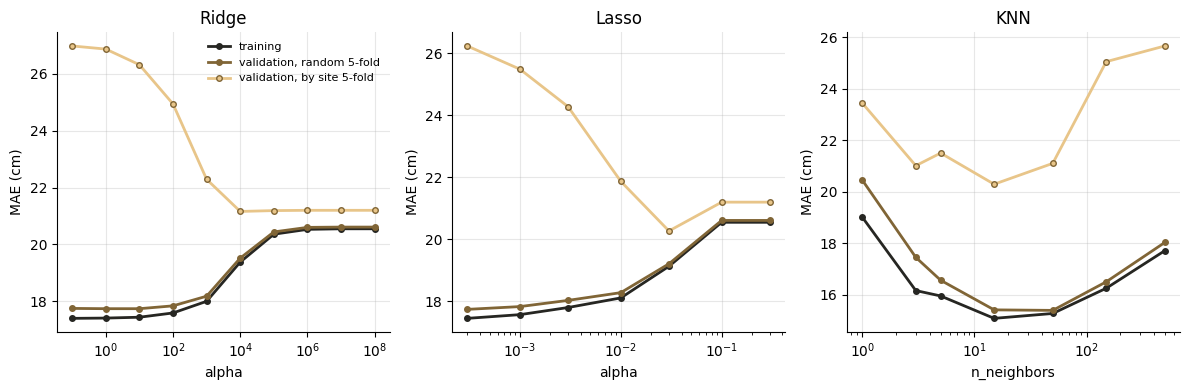

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, c) in zip(axes, curves.items()):
    # char ink / tundra ochre / sunlit tundra: well separated in lightness so training stands apart
    for col, color in zip(["training", "validation, random 5-fold", "validation, by site 5-fold"],
                          [COLORS[0], COLORS[2], COLORS[3]]):
        ax.plot(c.index, c[col], marker="o", ms=4, lw=2, color=color, label=col,
                mec=COLORS[2] if color == COLORS[3] else color)  # outline the light markers
    ax.set_xscale("log")
    ax.set(title=name, xlabel=c.index.name, ylabel="MAE (cm)")
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/validation_curves.png", dpi=200); plt.show()

### 5d. Split inflation

In [ ]:
grouped = ["By site (5-fold)", "By fire (5-fold)", "Leave-contributor-out"]
infl = pd.DataFrame({s: mae_table[s] - mae_table["Random (5-fold)"] for s in grouped}).round(2)
print("Increase in MAE compared with the random split (cm)")
display(infl)

Increase in MAE compared with the random split (cm)


,By site (5-fold),By fire (5-fold),Leave-contributor-out
model,,,
Median baseline,0.46,0.26,0.57
Group-mean baseline,1.26,3.64,14.32
Linear regression,9.38,4.55,49.15
Ridge,6.83,-0.59,-0.52
Lasso,7.14,0.18,0.84
KNN,11.29,4.00,5.95


### 5e. Comparison with baselines

In [ ]:
learned = ["Linear regression", "Ridge", "Lasso", "KNN"]
fold_sd = results["MAE fold SD"].unstack("split")
best = mae_table.loc[learned].idxmin()
cmp = pd.DataFrame({
    "best learned model": best,
    "MAE": [mae_table.loc[best[s], s] for s in split_order],
    "R²": [r2_table.loc[best[s], s] for s in split_order],
    "fold SD": [fold_sd.loc[best[s], s] for s in split_order],
    "median baseline": mae_table.loc["Median baseline", split_order],
    "group-mean baseline": mae_table.loc["Group-mean baseline", split_order],
}, index=split_order)
cmp["MAE − median baseline"] = (cmp["MAE"] - cmp["median baseline"]).round(2)
cmp["MAE − group-mean baseline"] = (cmp["MAE"] - cmp["group-mean baseline"]).round(2)
display(cmp)

,best learned model,MAE,R²,fold SD,median baseline,group-mean baseline,MAE − median baseline,MAE − group-mean baseline
Random (5-fold),KNN,16.71,0.45,1.81,20.21,19.05,-3.50,-2.34
By site (5-fold),Lasso,26.35,-0.27,10.07,20.67,20.31,5.68,6.04
By fire (5-fold),Lasso,19.39,0.08,1.92,20.47,22.69,-1.08,-3.30
Leave-contributor-out,Lasso,20.05,0.02,30.47,20.78,33.37,-0.73,-13.32
Alaska -> Canada,Ridge,21.68,-0.18,NaN,22.80,27.06,-1.12,-5.38
N. America -> Russia,KNN,17.80,0.37,NaN,24.89,27.67,-7.09,-9.87


### 5f. Site-level bootstrap confidence intervals

In [ ]:
# Resample held-out sites with replacement (2,000 times), keeping each split's predictions fixed;
# 95% intervals for MAE and for MAE minus the median baseline
B, rng = 2000, np.random.default_rng(SEED)
ci_rows = []
for s in split_order:
    p = all_preds[all_preds.split == s].assign(site=lambda t: d["site"].to_numpy()[t["row"]],
                                                abs_err=lambda t: np.abs(y[t["row"]] - t["pred"]))
    err = p.pivot_table(index="site", columns="model", values="abs_err", aggfunc="sum")[model_order]
    n = p[p.model == model_order[0]].groupby("site").size().loc[err.index].to_numpy()
    counts = rng.multinomial(len(n), np.full(len(n), 1 / len(n)), size=B)   # times each site is drawn
    boot = (counts @ err.to_numpy()) / (counts @ n)[:, None]               # bootstrap MAE, B x models
    diff = boot - boot[:, [model_order.index("Median baseline")]]
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    dlo, dhi = np.percentile(diff, [2.5, 97.5], axis=0)
    for j, m in enumerate(model_order):
        ci_rows.append({"split": s, "model": m, "test sites": len(n), "MAE": mae_table.loc[m, s],
                        "MAE 95% CI": f"{lo[j]:.1f} to {hi[j]:.1f}",
                        "MAE − median baseline 95% CI": "" if m == "Median baseline" else f"{dlo[j]:.1f} to {dhi[j]:.1f}"})
boot_ci = pd.DataFrame(ci_rows).set_index(["split", "model"])
display(boot_ci)

test sites    MAE    MAE 95% CI MAE − median baseline 95% CI
split                 model                                                                            
Random (5-fold)       Median baseline             197  20.21  15.1 to 28.3                             
                      Group-mean baseline         197  19.05  14.6 to 24.9                  -4.1 to 1.4
                      Linear regression           197  17.75  13.6 to 23.9                 -4.6 to -0.8
                      Ridge                       197  20.61  16.2 to 27.8                  -0.6 to 1.2
                      Lasso                       197  19.21  14.6 to 26.3                 -2.1 to -0.1
                      KNN                         197  16.71  13.4 to 20.5                 -8.7 to -0.5
By site (5-fold)      Median baseline             197  20.67  15.7 to 28.2                             
                      Group-mean baseline         197  20.31  16.2 to 26.1                  -3.0 to 1.9
                      Linear regression           197  27.13  18.5 to 35.4                 -3.2 to 17.5
                      Ridge                       197  27.44  19.3 to 35.0                 -1.6 to 16.9
                      Lasso                       197  26.35  18.9 to 33.1                 -2.0 to 14.9
                      KNN                         197  28.00  20.9 to 34.0                 -0.7 to 15.1
By fire (5-fold)      Median baseline             197  20.47  15.5 to 28.3                             
                      Group-mean baseline         197  22.69  18.0 to 29.7                  -0.6 to 5.5
                      Linear regression           197  22.30  17.2 to 29.7                  -0.8 to 5.2
                      Ridge                       197  20.02  15.7 to 26.9                  -1.6 to 0.4
                      Lasso                       197  19.39  15.2 to 26.1                 -2.5 to -0.0
                      KNN                         197  20.71  16.1 to 27.3                  -2.5 to 3.0
Leave-contributor-out Median baseline             197  20.78  15.8 to 28.1                             
                      Group-mean baseline         197  33.37  24.5 to 43.8                  6.8 to 20.4
                      Linear regression           197  66.90  43.9 to 93.4                 26.6 to 69.9
                      Ridge                       197  20.09  15.6 to 26.5                  -1.7 to 0.0
                      Lasso                       197  20.05  15.5 to 26.5                  -1.8 to 0.1
                      KNN                         197  22.66  17.2 to 29.9                  -2.0 to 6.7
Alaska -> Canada      Median baseline             114  22.80  18.8 to 27.2                             
                      Group-mean baseline         114  27.06  20.9 to 35.0                 -1.2 to 11.5
                      Linear regression           114  27.66  24.6 to 31.3                 -0.1 to 10.0
                      Ridge                       114  21.68  18.3 to 25.5                 -2.0 to -0.2
                      Lasso                       114  21.68  18.3 to 25.5                 -2.0 to -0.2
                      KNN                         114  48.98  28.1 to 70.4                  8.1 to 44.7
N. America -> Russia  Median baseline              25  24.89  20.4 to 32.3                             
                      Group-mean baseline          25  27.67  22.9 to 34.1                  -0.1 to 5.1
                      Linear regression            25  21.00  15.7 to 28.6                  -9.4 to 2.5
                      Ridge                        25  27.29  22.9 to 33.9                   1.1 to 3.3
                      Lasso                        25  27.60  22.5 to 34.0                  -0.6 to 5.5
                      KNN                          25  17.80  13.7 to 24.5                -11.5 to -2.3

## 6. Feature selection

### 6a. Adding left-out features

In [ ]:
FS_SPLITS = ["Random (5-fold)", "By site (5-fold)", "By fire (5-fold)", "Alaska -> Canada", "N. America -> Russia"]
d["year_cat"] = d["year"].astype(str)   # year as a category (one column per year)

# name -> (extra categorical features, extra numeric features)
variants = {"Lean (final)":           ([], []),
            "+ coordinates":          ([], EXTRA["coordinates"]),
            "+ year (numeric)":       ([], EXTRA["year"]),
            "+ year (categorical)":   (["year_cat"], []),
            "+ coordinates and year": (["year_cat"], EXTRA["coordinates"]),
            "+ organic layer depth":  ([], EXTRA["organic layer depth"]),
            "+ all three":            (["year_cat"], EXTRA["coordinates"] + EXTRA["organic layer depth"])}

add = []
for vname, (xc, xn) in variants.items():
    cat, num = CAT + xc, NUM + xn
    for s in FS_SPLITS:
        add.append(run_split(s, make_models(cat, num, ["Lasso"]), cat + num).assign(features=vname))
add_mae = score(pd.concat(add), by=("features", "split"))["MAE"].unstack("split").loc[list(variants), FS_SPLITS]
print("Lasso MAE (cm) with left-out features added")
display(add_mae)
print("Change compared with lean set (cm)")
display((add_mae - add_mae.loc["Lean (final)"]).round(2))

Lasso MAE (cm) with left-out features added


split,Random (5-fold),By site (5-fold),By fire (5-fold),Alaska -> Canada,N. America -> Russia
features,,,,,
Lean (final),19.21,26.35,19.39,21.68,27.60
+ coordinates,19.10,26.39,20.26,21.68,27.29
+ year (numeric),19.13,27.76,19.75,21.68,27.43
+ year (categorical),19.14,29.41,19.59,21.68,27.60
+ coordinates and year,19.10,29.45,20.28,21.68,27.29
+ organic layer depth,20.61,27.92,19.92,21.68,27.29
+ all three,20.61,31.15,19.86,21.68,27.29


Change compared with lean set (cm)


split,Random (5-fold),By site (5-fold),By fire (5-fold),Alaska -> Canada,N. America -> Russia
features,,,,,
Lean (final),0.00,0.00,0.00,0.0,0.00
+ coordinates,-0.11,0.04,0.87,0.0,-0.31
+ year (numeric),-0.08,1.41,0.36,0.0,-0.17
+ year (categorical),-0.07,3.06,0.20,0.0,0.00
+ coordinates and year,-0.11,3.10,0.89,0.0,-0.31
+ organic layer depth,1.40,1.57,0.53,0.0,-0.31
+ all three,1.40,4.80,0.47,0.0,-0.31


### 6b. Interaction terms

In [ ]:
# Categorical interactions: combined category labels; numeric: tsf, tsf² for boreal plots only
fill = lambda c: d[c].fillna("missing").astype(str)
d["burn_x_biome"] = fill("distur") + "|" + fill("biome")
d["burn_x_perma"] = fill("distur") + "|" + fill("permaExtent")
d["burn_x_veg"]   = fill("distur") + "|" + fill("vegCvr")
d["tsf_boreal"]   = d["tsf"] * (d["biome"] == "boreal")
d["tsf2_boreal"]  = d["tsf2"] * (d["biome"] == "boreal")

INTER = {
    "Lean (final)":              ([], []),
    "+ burned × biome":          (["burn_x_biome"], ["tsf_boreal", "tsf2_boreal"]),
    "+ burned × permafrost zone": (["burn_x_perma"], []),
    "+ burned × vegetation":     (["burn_x_veg"], []),
    "+ all interactions":        (["burn_x_biome", "burn_x_perma", "burn_x_veg"], ["tsf_boreal", "tsf2_boreal"]),
}
inter = []
for vname, (ic, inum) in INTER.items():
    cat, num = CAT + ic, NUM + inum
    for s in FS_SPLITS:
        inter.append(run_split(s, make_models(cat, num, ["Lasso"]), cat + num).assign(features=vname))
inter_mae = score(pd.concat(inter), by=("features", "split"))["MAE"].unstack("split").loc[list(INTER), FS_SPLITS]
print("Lasso MAE (cm) with interaction terms")
display(inter_mae)
print("Change compared with lean set (cm)")
display((inter_mae - inter_mae.loc["Lean (final)"]).round(2))

Lasso MAE (cm) with interaction terms


split,Random (5-fold),By site (5-fold),By fire (5-fold),Alaska -> Canada,N. America -> Russia
features,,,,,
Lean (final),19.21,26.35,19.39,21.68,27.60
+ burned × biome,18.89,24.93,19.51,77.09,25.92
+ burned × permafrost zone,19.11,23.59,18.88,20.56,27.47
+ burned × vegetation,18.94,22.58,19.75,20.58,25.74
+ all interactions,18.66,22.30,19.83,36.26,24.09


Change compared with lean set (cm)


split,Random (5-fold),By site (5-fold),By fire (5-fold),Alaska -> Canada,N. America -> Russia
features,,,,,
Lean (final),0.00,0.00,0.00,0.00,0.00
+ burned × biome,-0.32,-1.42,0.12,55.41,-1.68
+ burned × permafrost zone,-0.10,-2.76,-0.51,-1.12,-0.13
+ burned × vegetation,-0.27,-3.77,0.36,-1.10,-1.86
+ all interactions,-0.55,-4.05,0.44,14.58,-3.51


## 7. Leakage demonstration

In [ ]:
# Ridge on the cm scale, with and without the fields the label is computed from
leak = []
for vname, (cat, num) in {"Lean features": (CAT, NUM),
                          "+ leaky fields": (CAT + LEAKY_CAT, NUM + LEAKY_NUM)}.items():
    ridge_cm = lambda cat=cat, num=num: Pipeline([("prep", make_prep(cat, num)), ("model", Ridge())])
    for s in ["Random (5-fold)", "By site (5-fold)", "By fire (5-fold)"]:
        leak.append(run_split(s, {"Ridge": (ridge_cm, {"model__alpha": GRIDS["Ridge"]})}, cat + num)
                    .assign(features=vname))
leak_res = score(pd.concat(leak), by=("features", "split"))[["MAE", "RMSE", "R2"]]
display(leak_res)

MAE   RMSE    R2
features       split                               
Lean features  Random (5-fold)   22.16  33.37 -0.00
               By site (5-fold)  34.32  46.97 -0.98
               By fire (5-fold)  21.53  32.37  0.06
+ leaky fields Random (5-fold)    4.05   7.10  0.95
               By site (5-fold)   5.84   8.92  0.93
               By fire (5-fold)   5.69   9.58  0.92

## 8. Learned model

### 8a. Lasso coefficients

In [ ]:
make, grid = MODELS["Lasso"]
lasso, alpha = fit_model(make, grid, d[CAT + NUM], y, d["site"])
names = lasso.regressor_.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lasso.regressor_.named_steps["model"].coef_, index=names)
coef.index = coef.index.str.replace("cat__", "").str.replace("num__", "")
print(f"Lasso alpha = {alpha}: {(coef == 0).sum()} of {len(coef)} coefficients set to 0")
top = coef[coef != 0].sort_values(key=abs, ascending=False)
display(top.to_frame("coefficient (log scale)").assign(**{"≈ % change in ALT": (100 * np.expm1(top)).round(1)}).round(3))

Lasso alpha = 0.03: 43 of 45 coefficients set to 0


,coefficient (log scale),≈ % change in ALT
distur_burned,0.152,16.4
tsf2,-0.026,-2.6


### 8b. Time-since-fire curve

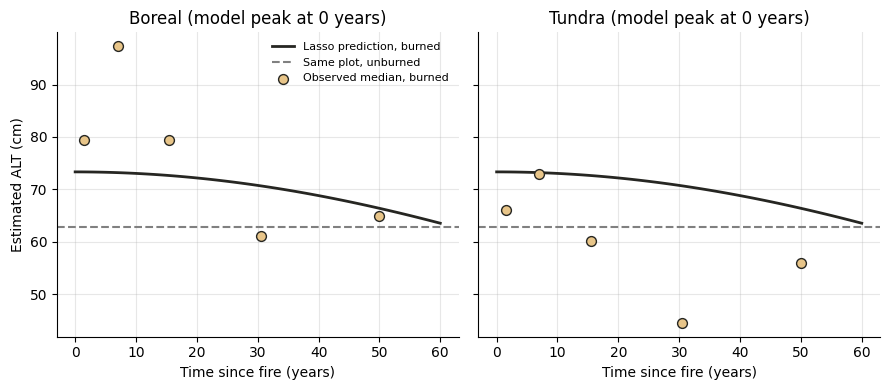

In [ ]:
# Lasso prediction for a typical burned plot (most common category values per biome), tsf = 0–60
grid_tsf = np.arange(0, 61)
class_mid = {"0-3": 1.5, "4-10": 7, "11-20": 15.5, "21-40": 30.5, ">40": 50}
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, biome in zip(axes, ["boreal", "tundra"]):
    typical = d[burned & (d.biome == biome)][CAT].mode().iloc[[0]]
    plot_rows = pd.concat([typical] * len(grid_tsf), ignore_index=True)
    plot_rows["tsf"], plot_rows["tsf2"] = grid_tsf, grid_tsf ** 2
    curve = lasso.predict(plot_rows[CAT + NUM])
    unb = typical.assign(distur="unburned", tsf=0.0, tsf2=0.0)
    ax.plot(grid_tsf, curve, lw=2, color=COLORS[0], label="Lasso prediction, burned")
    ax.axhline(lasso.predict(unb[CAT + NUM])[0], ls="--", c="gray", label="Same plot, unburned")
    obs = d[burned & (d.biome == biome)].groupby("tsfClass")[TARGET].median()
    ax.scatter([class_mid[c] for c in obs.index if c in class_mid],
               [obs[c] for c in obs.index if c in class_mid], c=COLORS[3], edgecolors=COLORS[0], linewidths=1, s=50, zorder=3,
               label="Observed median, burned")
    ax.set(title=f"{biome.capitalize()} (model peak at {grid_tsf[np.argmax(curve)]} years)",
           xlabel="Time since fire (years)")
axes[0].set_ylabel("Estimated ALT (cm)"); axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/tsf_curve.png", dpi=200); plt.show()

## 9. Error analysis

### 9a. By subgroup (by-fire split)

In [ ]:
def breakdown(preds, cols, models=("Median baseline", "Ridge", "Lasso", "KNN")):
    # MAE per subgroup, with number of plot-years and sites
    p = preds[preds.model.isin(models)].join(d[list(cols) + ["site"]], on="row")
    p["abs_err"] = np.abs(y[p["row"]] - p["pred"])
    mae_by = p.pivot_table(index=list(cols), columns="model", values="abs_err", aggfunc="mean")
    n = p[p.model == models[0]].groupby(list(cols)).agg(n=("row", "size"), sites=("site", "nunique"))
    return n.join(mae_by.round(1)[list(models)]).sort_values("n", ascending=False)

fire_p = all_preds[all_preds.split == "By fire (5-fold)"]
for cols in (["biome", "distur"], ["tsfClass"]):
    display(breakdown(fire_p, cols))

n  sites  Median baseline  Ridge  Lasso   KNN
biome  distur                                                    
boreal unburned  3799     69             13.2   13.6   13.2  14.1
       burned    3288    104             32.0   29.4   28.1  32.3
tundra burned    1294     28             17.5   18.0   19.6  16.6
       unburned  1065     27             14.4   16.5   14.5  13.6

,n,sites,Median baseline,Ridge,Lasso,KNN
tsfClass,,,,,,
unburned,4864,96,13.5,14.2,13.5,14.0
0-3,1629,63,23.5,20.8,20.4,20.7
4-10,1034,47,45.6,41.5,38.9,40.3
>40,825,30,18.6,19.4,20.1,28.3
21-40,616,17,22.6,24.4,26.1,22.9
11-20,478,24,27.2,25.3,24.1,30.9


### 9b. By contributor (leave-contributor-out)

In [ ]:
loco = breakdown(all_preds[all_preds.split == "Leave-contributor-out"], ["submitNm"],
                 models=("Median baseline", "Linear regression", "Ridge", "Lasso", "KNN"))
display(loco.join(d.groupby("submitNm")["region"].first()))

### 9c. By-site folds

In [ ]:
site_p = all_preds[all_preds.split == "By site (5-fold)"]
rows = []
for k, (tr, te) in enumerate(SPLITS["By site (5-fold)"]):
    t = d.iloc[te]; big = t["site"].value_counts()
    row = {"fold": k, "plot-years": len(te), "sites": len(big), "largest site": big.index[0],
           "share of fold": round(big.iloc[0] / len(te), 2), "burned share": round((t.distur == "burned").mean(), 2),
           "mean ALT (cm)": round(t[TARGET].mean(), 1)}
    for m in ["Median baseline", "Group-mean baseline", "Ridge", "Lasso", "KNN"]:
        f = site_p[(site_p.model == m) & (site_p.fold == k)]
        row[m] = round(mean_absolute_error(y[f["row"]], f["pred"]), 1)
    rows.append(row)
site_folds = pd.DataFrame(rows).set_index("fold")
display(site_folds)

# Mean prediction vs mean observed ALT in each by-site fold
display(site_p.assign(obs=y[site_p["row"]]).groupby(["fold", "model"])[["pred", "obs"]].mean()
        .round(1).unstack("model")["pred"][["Median baseline", "Ridge", "Lasso", "KNN"]]
        .assign(observed=site_folds["mean ALT (cm)"]))

,plot-years,sites,largest site,share of fold,burned share,mean ALT (cm),Median baseline,Group-mean baseline,Ridge,Lasso,KNN
fold,,,,,,,,,,,
0,1936,1,Douglas|Farmers CALM,1.00,0.00,58.0,10.2,11.0,45.5,42.0,38.9
1,1878,49,Olefeldt|lutose_2000,0.27,0.71,86.9,32.5,28.9,30.0,29.9,32.8
2,1878,50,Baillargeon|d,0.19,0.62,77.4,24.0,21.5,23.5,23.5,23.2
3,1877,49,Baillargeon|b,0.19,0.56,70.2,18.5,21.2,18.9,18.2,19.9
4,1877,48,Baillargeon|a,0.18,0.55,70.6,18.5,19.1,18.7,17.6,24.8


model,Median baseline,Ridge,Lasso,KNN,observed
fold,,,,,
0,66.0,103.4,99.8,96.8,58.0
1,61.8,71.9,72.0,73.1,86.9
2,62.0,66.3,66.3,73.2,77.4
3,63.0,67.3,68.4,74.0,70.2
4,62.5,67.1,67.6,75.4,70.6


### 9d. Test rows with categories unseen in training

In [ ]:
# Flag held-out rows with at least one category value that never appears in that fold's training data
def unseen_flags(split_name):
    flag = pd.Series(False, index=idx)
    for tr, te in SPLITS[split_name]:
        for c in CAT:
            seen = set(d[c].iloc[tr].fillna("missing").astype(str))
            flag.iloc[te] |= ~d[c].iloc[te].fillna("missing").astype(str).isin(seen).to_numpy()
    return flag

rows = []
for s in split_order:
    flag = unseen_flags(s)
    p = all_preds[all_preds.split == s].assign(unseen=lambda t: flag.loc[t["row"]].to_numpy(),
                                                abs_err=lambda t: np.abs(y[t["row"]] - t["pred"]))
    tested = np.concatenate([te for _, te in SPLITS[s]])
    row = {"split": s, "share of test rows": round(flag.iloc[tested].mean(), 3)}
    for m in ["Median baseline", "Linear regression", "Ridge", "Lasso", "KNN"]:
        pm = p[p.model == m]
        row[f"{m}, seen"] = round(pm[~pm.unseen].abs_err.mean(), 1)
        row[f"{m}, unseen"] = round(pm[pm.unseen].abs_err.mean(), 1) if pm.unseen.any() else np.nan
    rows.append(row)
display(pd.DataFrame(rows).set_index("split"))

# Which categories are unseen in each region-transfer test set
for s in ["Alaska -> Canada", "N. America -> Russia"]:
    tr, te = SPLITS[s][0]
    print(f"\n{s}: categories in test set not in training set (plot-years)")
    for c in CAT:
        vals = d[c].iloc[te].fillna("missing").astype(str)
        new = vals[~vals.isin(set(d[c].iloc[tr].fillna("missing").astype(str)))].value_counts()
        if len(new):
            print(f"  {c}: {dict(new)}")

,share of test rows,"Median baseline, seen","Median baseline, unseen","Linear regression, seen","Linear regression, unseen","Ridge, seen","Ridge, unseen","Lasso, seen","Lasso, unseen","KNN, seen","KNN, unseen"
split,,,,,,,,,,,
Random (5-fold),0.000,20.2,55.9,17.7,22.0,20.6,51.9,19.2,47.5,16.7,34.0
By site (5-fold),0.002,20.7,17.4,27.1,18.9,27.5,16.6,26.4,14.9,28.0,21.2
By fire (5-fold),0.060,20.6,19.0,21.1,41.1,19.8,22.8,19.1,23.8,21.1,14.1
Leave-contributor-out,0.082,20.8,20.8,71.0,20.4,19.8,23.4,19.7,23.6,23.0,19.3
Alaska -> Canada,1.000,NaN,22.8,NaN,27.7,NaN,21.7,NaN,21.7,NaN,49.0
N. America -> Russia,1.000,NaN,24.9,NaN,21.0,NaN,27.3,NaN,27.6,NaN,17.8



Alaska -> Canada: categories in test set not in training set (plot-years)
  vegCvr: {'DN': np.int64(10), 'BD': np.int64(1)}
  resName: {'Muskwa-Slave Lake taiga': np.int64(3301), 'Northwest Territories taiga': np.int64(1252), 'Northern Canadian Shield taiga': np.int64(31)}
  permaExtent: {'S': np.int64(3310)}

N. America -> Russia: categories in test set not in training set (plot-years)
  vegCvr: {'M': np.int64(2)}
  resName: {'Chukchi Peninsula tundra': np.int64(495), 'Northeast Siberian taiga': np.int64(141), 'East Siberian taiga': np.int64(52), 'Yamal-Gydan tundra': np.int64(3)}


## 10. Regional transfer

### 10a. Contributors per region

In [ ]:
display(d.groupby("region").agg(plot_years=(TARGET, "size"), sites=("site", "nunique"),
                                contributors=("submitNm", "nunique"), fires=("fireId", "nunique"),
                                fire_groups=("fire_group", "nunique")))
comp = d.groupby(["region", "submitNm"]).agg(plot_years=(TARGET, "size"), sites=("site", "nunique"))
comp["% of region"] = (100 * comp.plot_years / comp.groupby("region").plot_years.transform("sum")).round(0)
display(comp.sort_values(["region", "plot_years"], ascending=[True, False]))

### 10b. Error by contributor

In [ ]:
for s in ["Alaska -> Canada", "N. America -> Russia"]:
    print(f"{s}: MAE by research team")
    display(breakdown(all_preds[all_preds.split == s], ["submitNm"]))

### 10c. Error by biome and permafrost zone

In [ ]:
for s in ["Alaska -> Canada", "N. America -> Russia"]:
    for cols in (["biome"], ["permaExtent"]):
        print(f"{s}: MAE by {', '.join(cols)}")
        display(breakdown(all_preds[all_preds.split == s], cols))

## 11. Figures

### 11a. MAE by split

In [ ]:
show = ["Median baseline", "Group-mean baseline", "Lasso", "KNN"]
x = np.arange(len(split_order)); w = 0.2
fig, ax = plt.subplots(figsize=(11, 4.5))
five_fold = [s for s in split_order if "5-fold" in s]   # error bars only for the equal-size 5-fold splits
for i, (m, color) in enumerate(zip(show, COLORS)):
    err = [fold_sd.loc[m, s] if s in five_fold else np.nan for s in split_order]
    ax.bar(x + (i - 1.5) * w, mae_table.loc[m, split_order], w * 0.92, yerr=err, capsize=2,
           color=color, label=m, error_kw={"lw": 0.8, "ecolor": "#555"})
ax.set_xticks(x, [s.replace(" (5-fold)", "") for s in split_order], rotation=15, ha="right")
ax.set(ylabel="MAE (cm)", ylim=(0, None),
       title="Held-out MAE by split")
ax.legend(ncol=4, fontsize=10, frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/mae_by_split.png", dpi=200); plt.show()

### 11b. Leakage

In [ ]:
lt = leak_res["MAE"].unstack("features")[["Lean features", "+ leaky fields"]]
x = np.arange(len(lt)); w = 0.35
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, (col, color) in enumerate(zip(lt.columns, COLORS)):
    bars = ax.bar(x + (i - 0.5) * w, lt[col], w * 0.92, color=color, label=col)
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
ax.set_xticks(x, [s.replace(" (5-fold)", "") for s in lt.index])
ax.set(ylabel="MAE (cm)", title="Ridge MAE with and without leaky fields")
ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/leakage.png", dpi=200); plt.show()

### 11c. By-site folds

In [ ]:
show = ["Median baseline", "Ridge", "Lasso", "KNN"]
x = np.arange(len(site_folds)); w = 0.2
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (m, color) in enumerate(zip(show, COLORS)):
    ax.bar(x + (i - 1.5) * w, site_folds[m], w * 0.92, color=color, label=m)
ax.set_xticks(x, [f"Fold {k}\n{s}" for k, s in site_folds["largest site"].items()], fontsize=8)
ax.set(ylabel="MAE (cm)", title="By-site split: MAE per test fold (label: largest site)")
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper right")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/site_folds.png", dpi=200); plt.show()
print("Saved:", sorted(os.listdir(FIG_DIR)))